# Aggregate Baseball Savant pitch-tempo benchmark

This notebook tests whether feed-derived event-start and event-end intervals reproduce Baseball Savant's published 2024 regular-season pitcher medians for six pitchers selected before feed agreement was calculated. It is aggregate corroboration, not independent validation of individual releases. The public-video gate remains `validation_pending`, and no runner-threat model or causal analysis appears here.


## Frozen design

The design in `docs/aggregate_tempo_benchmark_protocol.md` was frozen before agreement was inspected. Primary eligibility follows Savant's documented rule: consecutive actual pitches to the same batter and pitcher, with the preceding pitch called `Ball` or `Called Strike`. Base state is reconstructed immediately before the following pitch. Long and action-interrupted intervals remain in the primary analysis. Start-to-start and end-to-end are reported in parallel; neither is selected post hoc as a release timestamp.


In [1]:
from datetime import datetime, timezone
from pathlib import Path
import platform
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.tempo_benchmark import (
    action_inventory, add_benchmark_differences, coverage_summary, load_and_build,
    published_long, summarize_measure,
)

executed_utc = datetime.now(timezone.utc).isoformat(timespec='seconds').replace('+00:00', 'Z')
environment = pd.DataFrame([
    {'package': 'Python', 'version': platform.python_version()},
    {'package': 'pandas', 'version': pd.__version__},
    {'package': 'numpy', 'version': np.__version__},
    {'package': 'matplotlib', 'version': matplotlib.__version__},
])
print(f'Executed UTC: {executed_utc}')
display(environment)


Executed UTC: 2026-11-15T22:32:38Z


,package,version
0,Python,3.14.4
1,pandas,3.0.2
2,numpy,2.4.4
3,matplotlib,3.10.8


In [2]:
DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
pitchers, manifest, events, pairs = load_and_build(ROOT)
video_gate = pd.read_csv(RESULTS / 'video_timing_validation_summary.csv')
source_checks = pd.read_csv(DATA / 'tempo_benchmark_source_checks.csv')

assert len(pitchers) == 6 and pitchers['entity_id'].is_unique
assert len(manifest) == 182 and manifest['game_pk'].is_unique
assert set(pitchers['entity_id'].astype(int)).issubset(set(events['pitcher_id'].dropna().astype(int)))
assert pairs[['game_pk', 'at_bat_index', 'preceding_event_index', 'following_event_index']].duplicated().sum() == 0
assert video_gate.loc[0, 'outcome'] == 'validation_pending'

print(f'Loaded {len(manifest)} games, {len(events):,} feed events, and {len(pairs):,} adjacent actual-pitch pairs.')
print('Frozen video gate:', video_gate.loc[0, 'outcome'])
display(pitchers)
display(source_checks)


Loaded 182 games, 62,321 feed events, and 40,063 adjacent actual-pitch pairs.
Frozen video gate: validation_pending


,selection_position,entity_id,entity_name,team_name,savant_total_eligible,savant_empty_count,savant_empty_median_seconds,savant_onbase_count,savant_onbase_median_seconds,is_qualified,selection_rule_version
0,1,681867,"Criswell, Cooper",BOS,843,515,11.633,328,15.869,1,tempo-benchmark-v1
1,23,641927,"Ober, Bailey",MIN,1115,824,13.802,291,20.413,1,tempo-benchmark-v1
2,45,668678,"Gallen, Zac",AZ,1108,741,14.525,367,19.606,1,tempo-benchmark-v1
3,67,544150,"Suárez, Albert",BAL,956,574,15.483,382,18.763,1,tempo-benchmark-v1
4,89,687765,"Spence, Mitch",ATH,1027,680,16.421,347,19.776,1,tempo-benchmark-v1
5,111,605400,"Nola, Aaron",PHI,1383,923,18.905,460,20.911,1,tempo-benchmark-v1


,checked_utc,season,embedded_rows,selection_pool_rows,qualified_rows,observed_minimum_qualified_total,observed_maximum_unqualified_total,csv_data_rows,csv_duplicate_headers,csv_first_row_onbase_value_repeats_empty,visible_rounding_decimals,embedded_median_decimals,notes
0,2026-11-15T22:32:21Z,2024,854,111,378,324,321,854,median_seconds_empty | total_pitches,True,1,3,Embedded tempoServerVals.data used for benchma...


In [3]:
coverage = coverage_summary(events, pairs, pitchers)
actions = action_inventory(pairs, pitchers)
display(coverage)
display(actions)
print('No long or action-interrupted documented-rule pair is silently excluded from the primary summaries.')


,pitcher_id,pitcher_name,games,feed_pitch_events,actual_pitch_events,adjacent_actual_pitch_pairs,documented_rule_pairs,interrupted_documented_pairs,missing_start_intervals,nonpositive_start_intervals,missing_end_intervals,nonpositive_end_intervals,start_intervals_over_30,end_intervals_over_30
0,681867,"Criswell, Cooper",26,1756,1756,1331,903,60,0,0,0,0,21,22
1,641927,"Ober, Bailey",31,2696,2696,1986,1175,60,0,0,0,0,35,58
2,668678,"Gallen, Zac",28,2502,2502,1881,1222,116,0,0,0,0,79,94
3,544150,"Suárez, Albert",32,2234,2234,1669,1024,68,0,0,0,0,44,62
4,687765,"Spence, Mitch",35,2481,2481,1826,1102,75,0,0,0,0,55,70
5,605400,"Nola, Aaron",33,3189,3189,2365,1489,106,0,0,0,0,89,129


,base_state,action_category,pairs
3,bases_empty,timeout,173
1,bases_empty,other_nonpitch,9
0,bases_empty,mound_visit,8
2,bases_empty,pickoff,1
6,runners_on,pickoff,114
8,runners_on,timeout,74
5,runners_on,other_nonpitch,67
7,runners_on,step_off,38
4,runners_on,mound_visit,15


No long or action-interrupted documented-rule pair is silently excluded from the primary summaries.


In [4]:
primary_parts = []
for value_column in ('start_to_start_seconds', 'end_to_end_seconds'):
    primary_parts.append(summarize_measure(
        pairs, pitchers, value_column=value_column, scenario='documented_rules'
    ))
primary_summary = pd.concat(primary_parts, ignore_index=True)
comparison = add_benchmark_differences(primary_summary, pitchers)
comparison = comparison.sort_values(['timestamp_measure', 'base_state', 'pitcher_name']).reset_index(drop=True)
display(comparison[[
    'pitcher_name', 'base_state', 'timestamp_measure', 'feed_eligible_intervals',
    'savant_eligible_intervals', 'count_difference', 'feed_median_seconds',
    'savant_median_seconds', 'difference_seconds', 'absolute_difference_seconds',
    'action_interrupted', 'over_30_seconds',
]])

discrepancy_summary = (
    comparison.groupby(['timestamp_measure', 'base_state'])
    .agg(
        pitcher_cells=('pitcher_id', 'size'),
        median_signed_difference=('difference_seconds', 'median'),
        median_absolute_discrepancy=('absolute_difference_seconds', 'median'),
        maximum_absolute_discrepancy=('absolute_difference_seconds', 'max'),
        median_count_difference=('count_difference', 'median'),
        maximum_absolute_count_difference=('count_difference', lambda values: values.abs().max()),
    )
    .reset_index()
)
display(discrepancy_summary)


,pitcher_name,base_state,timestamp_measure,feed_eligible_intervals,savant_eligible_intervals,count_difference,feed_median_seconds,savant_median_seconds,difference_seconds,absolute_difference_seconds,action_interrupted,over_30_seconds
0,"Criswell, Cooper",bases_empty,end_to_end,547,515,32,12.7810,11.633,1.1480,1.1480,32,4
1,"Gallen, Zac",bases_empty,end_to_end,774,741,33,15.3815,14.525,0.8565,0.8565,33,9
2,"Nola, Aaron",bases_empty,end_to_end,965,923,42,19.7420,18.905,0.8370,0.8370,42,50
3,"Ober, Bailey",bases_empty,end_to_end,859,824,35,14.6460,13.802,0.8440,0.8440,35,21
4,"Spence, Mitch",bases_empty,end_to_end,705,680,25,17.5530,16.421,1.1320,1.1320,25,17
5,"Suárez, Albert",bases_empty,end_to_end,595,574,21,16.3650,15.483,0.8820,0.8820,21,16
6,"Criswell, Cooper",runners_on,end_to_end,356,328,28,16.8530,15.869,0.9840,0.9840,28,18
7,"Gallen, Zac",runners_on,end_to_end,448,367,81,20.8660,19.606,1.2600,1.2600,83,85
8,"Nola, Aaron",runners_on,end_to_end,524,460,64,22.1900,20.911,1.2790,1.2790,64,79
9,"Ober, Bailey",runners_on,end_to_end,316,291,25,21.2835,20.413,0.8705,0.8705,25,37


,timestamp_measure,base_state,pitcher_cells,median_signed_difference,median_absolute_discrepancy,maximum_absolute_discrepancy,median_count_difference,maximum_absolute_count_difference
0,end_to_end,bases_empty,6,0.86925,0.86925,1.148,32.5,42
1,end_to_end,runners_on,6,1.17750,1.17750,1.618,48.5,81
2,start_to_start,bases_empty,6,0.09850,0.09850,0.162,32.5,42
3,start_to_start,runners_on,6,0.28350,0.28350,0.524,48.5,81


In [5]:
rounding = comparison[[
    'pitcher_name', 'base_state', 'timestamp_measure', 'feed_median_seconds',
    'savant_median_seconds', 'feed_display_seconds', 'savant_display_seconds',
    'difference_seconds', 'display_difference_seconds',
]].copy()
rounding['rounding_changed_absolute_discrepancy'] = (
    rounding['display_difference_seconds'].abs() - rounding['difference_seconds'].abs()
)
display(rounding)


,pitcher_name,base_state,timestamp_measure,feed_median_seconds,savant_median_seconds,feed_display_seconds,savant_display_seconds,difference_seconds,display_difference_seconds,rounding_changed_absolute_discrepancy
0,"Criswell, Cooper",bases_empty,end_to_end,12.7810,11.633,12.8,11.6,1.1480,1.2,0.0520
1,"Gallen, Zac",bases_empty,end_to_end,15.3815,14.525,15.4,14.5,0.8565,0.9,0.0435
2,"Nola, Aaron",bases_empty,end_to_end,19.7420,18.905,19.7,18.9,0.8370,0.8,-0.0370
3,"Ober, Bailey",bases_empty,end_to_end,14.6460,13.802,14.6,13.8,0.8440,0.8,-0.0440
4,"Spence, Mitch",bases_empty,end_to_end,17.5530,16.421,17.6,16.4,1.1320,1.2,0.0680
5,"Suárez, Albert",bases_empty,end_to_end,16.3650,15.483,16.4,15.5,0.8820,0.9,0.0180
6,"Criswell, Cooper",runners_on,end_to_end,16.8530,15.869,16.9,15.9,0.9840,1.0,0.0160
7,"Gallen, Zac",runners_on,end_to_end,20.8660,19.606,20.9,19.6,1.2600,1.3,0.0400
8,"Nola, Aaron",runners_on,end_to_end,22.1900,20.911,22.2,20.9,1.2790,1.3,0.0210
9,"Ober, Bailey",runners_on,end_to_end,21.2835,20.413,21.3,20.4,0.8705,0.9,0.0295


In [6]:
sensitivity_parts = []
for value_column in ('start_to_start_seconds', 'end_to_end_seconds'):
    for scenario in ('no_intervening_actions', 'at_most_30_seconds'):
        sensitivity_parts.append(summarize_measure(
            pairs, pitchers, value_column=value_column, scenario=scenario
        ))
    preceding_state = summarize_measure(
        pairs, pitchers, value_column=value_column, scenario='documented_rules',
        state_column='preceding_state',
    )
    preceding_state['scenario'] = 'preceding_state_classification'
    sensitivity_parts.append(preceding_state)
sensitivity = add_benchmark_differences(
    pd.concat(sensitivity_parts, ignore_index=True), pitchers
)
sensitivity_summary = (
    sensitivity.groupby(['timestamp_measure', 'scenario', 'base_state'])
    .agg(
        median_absolute_discrepancy=('absolute_difference_seconds', 'median'),
        maximum_absolute_discrepancy=('absolute_difference_seconds', 'max'),
        total_feed_intervals=('feed_eligible_intervals', 'sum'),
        total_savant_intervals=('savant_eligible_intervals', 'sum'),
    )
    .reset_index()
)
display(sensitivity_summary)


,timestamp_measure,scenario,base_state,median_absolute_discrepancy,maximum_absolute_discrepancy,total_feed_intervals,total_savant_intervals
0,end_to_end,at_most_30_seconds,bases_empty,0.78600,1.0960,4328,4257
1,end_to_end,at_most_30_seconds,runners_on,0.69150,0.9885,2152,2175
2,end_to_end,no_intervening_actions,bases_empty,0.70350,1.0005,4257,4257
3,end_to_end,no_intervening_actions,runners_on,0.71525,0.9990,2173,2175
4,end_to_end,preceding_state_classification,bases_empty,0.86200,1.1480,4440,4257
5,end_to_end,preceding_state_classification,runners_on,1.17875,1.6180,2475,2175
6,start_to_start,at_most_30_seconds,bases_empty,0.08325,0.1615,4389,4257
7,start_to_start,at_most_30_seconds,runners_on,0.07175,0.0880,2203,2175
8,start_to_start,no_intervening_actions,bases_empty,0.00250,0.0165,4257,4257
9,start_to_start,no_intervening_actions,runners_on,0.00100,0.0265,2173,2175


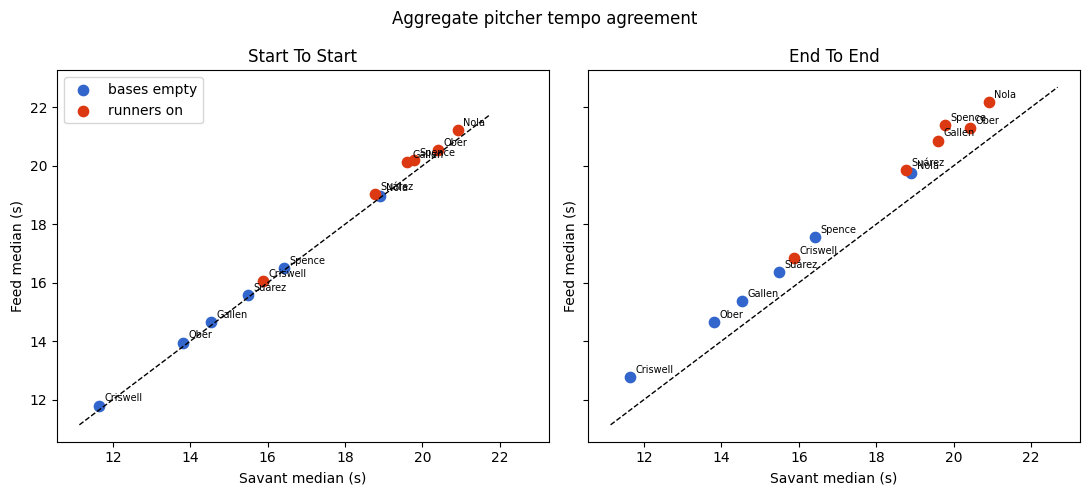

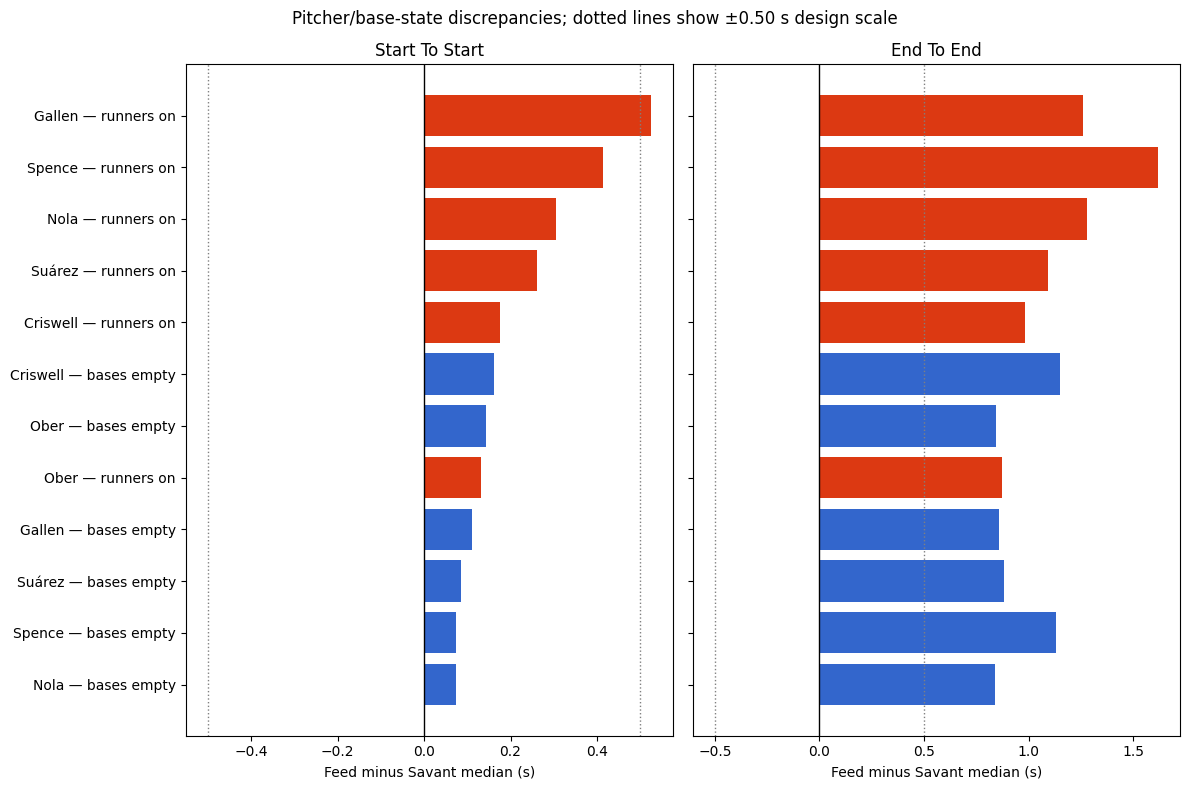

In [7]:
colors = {'bases_empty': '#3366cc', 'runners_on': '#dc3912'}
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, measure in zip(axes, ('start_to_start', 'end_to_end')):
    panel = comparison.loc[comparison['timestamp_measure'].eq(measure)]
    for state, group in panel.groupby('base_state'):
        ax.scatter(
            group['savant_median_seconds'], group['feed_median_seconds'],
            label=state.replace('_', ' '), color=colors[state], s=55,
        )
        for row in group.itertuples():
            ax.annotate(row.pitcher_name.split(',')[0],
                        (row.savant_median_seconds, row.feed_median_seconds),
                        xytext=(4, 3), textcoords='offset points', fontsize=7)
    low = min(panel['savant_median_seconds'].min(), panel['feed_median_seconds'].min()) - 0.5
    high = max(panel['savant_median_seconds'].max(), panel['feed_median_seconds'].max()) + 0.5
    ax.plot([low, high], [low, high], color='black', linestyle='--', linewidth=1)
    ax.set(title=measure.replace('_', ' ').title(), xlabel='Savant median (s)', ylabel='Feed median (s)')
axes[0].legend()
fig.suptitle('Aggregate pitcher tempo agreement')
fig.tight_layout()
fig.savefig(RESULTS / 'tempo_benchmark_agreement.png', dpi=160)
plt.show()

plot_frame = comparison.copy()
plot_frame['label'] = plot_frame['pitcher_name'].str.split(',').str[0] + ' — ' + plot_frame['base_state'].str.replace('_', ' ')
fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)
for ax, measure in zip(axes, ('start_to_start', 'end_to_end')):
    panel = plot_frame.loc[plot_frame['timestamp_measure'].eq(measure)].sort_values('difference_seconds')
    ax.barh(panel['label'], panel['difference_seconds'], color=[colors[state] for state in panel['base_state']])
    ax.axvline(0, color='black', linewidth=1)
    ax.axvline(0.5, color='gray', linestyle=':', linewidth=1)
    ax.axvline(-0.5, color='gray', linestyle=':', linewidth=1)
    ax.set(title=measure.replace('_', ' ').title(), xlabel='Feed minus Savant median (s)')
fig.suptitle('Pitcher/base-state discrepancies; dotted lines show ±0.50 s design scale')
fig.tight_layout()
fig.savefig(RESULTS / 'tempo_benchmark_discrepancies.png', dpi=160)
plt.show()


In [8]:
RESULTS.mkdir(exist_ok=True)
coverage.to_csv(RESULTS / 'tempo_benchmark_coverage.csv', index=False)
actions.to_csv(RESULTS / 'tempo_benchmark_action_inventory.csv', index=False)
comparison.to_csv(RESULTS / 'tempo_benchmark_pitcher_comparison.csv', index=False)
discrepancy_summary.to_csv(RESULTS / 'tempo_benchmark_discrepancy_summary.csv', index=False)
rounding.to_csv(RESULTS / 'tempo_benchmark_rounding.csv', index=False)
sensitivity.to_csv(RESULTS / 'tempo_benchmark_sensitivity.csv', index=False)
sensitivity_summary.to_csv(RESULTS / 'tempo_benchmark_sensitivity_summary.csv', index=False)
environment.assign(executed_utc=executed_utc).to_csv(
    RESULTS / 'tempo_benchmark_environment.csv', index=False
)
print('Wrote compact benchmark results; raw leaderboard, game logs, and feeds remain ignored.')


Wrote compact benchmark results; raw leaderboard, game logs, and feeds remain ignored.


## Interpretation boundary

Agreement here can support aggregate consistency only. It cannot establish exact release timestamps, independence from Savant's underlying data, individual-interval accuracy, validity for interruptions, sensitivity to small within-pitcher runner-threat responses, or causality. The frozen public-video gate remains pending regardless of this result.
